# VERIONCO — Notebook 07: Orchestrator + Red-Team + Blind Second Opinion

**Purpose:** Implement Agents 14–16 from the master prompt:

- **Agent 14 (Orchestrator):** Synthesize all NB06 plans into one primary recommendation by
  selecting from a deterministically ranked CANDIDATE_THERAPIES list.
- **Agent 15 (Red-Team):** Adversarially attempt to disprove the primary recommendation
  using NB05 counter-evidence.
- **Agent 16 (Blind Second Opinion):** Independently regenerate a recommendation from the
  same candidate list, with the primary recommendation withheld.

**Central scientific question (from master prompt §2):**
> Does adversarial red-teaming plus blind independent regeneration catch
> clinically important recommendation errors that agreement-based or single-pass
> systems silently miss, and does agreement between independent paths actually
> predict correctness or merely predict shared bias?

**v2 changes from v1:**
- Deterministic therapy candidate ranking (`rank_therapy_candidates`) prevents the
  LLM from punting to generic "do more testing" language.
- Orchestrator and second-opinion prompts now FORCE selection from the candidate list.
- `exact_treatment_match` uses normalized names, plus new signals:
  `named_drug_match`, `both_escalated`.
- Punt diagnostic added after flatten to monitor `primary_is_punt` rate.

**Design principles:**
- Three API calls per patient: (A) orchestrator, (B) red-team, (C) blind second opinion.
- **Blindness enforced in code:** the second-opinion prompt builder has no access to
  the primary recommendation variable. Cache keys differ.
- Silent failure is NOT computed here — only its preconditions are recorded.
- All LLM outputs cached by (patient, agent, prompt_version, model, evidence_hash).
- Deterministic fallback when API fails.
- Restartable: cached patients skipped instantly.

**Leakage contract:** every artifact keyed by `patient_id`.

**Downstream handoff:** NB08 consumes `orchestration_per_patient/{pid}.json` for
calibration, safety-gate, and silent-failure precondit

In [1]:

# Detect environment
IS_KAGGLE = Path("/kaggle").exists()

def find_dir(candidates, fallback):
    for c in candidates:
        p = Path(c)
        if p.exists():
            return p
    return Path(fallback)

# ============================================================
# CONFIGURATION  ← edit only this cell
# ============================================================
from pathlib import Path
import os, gc, sys, json, re, time, gc, hashlib, math
from datetime import datetime, timezone
from collections import defaultdict, Counter

import numpy as np
import pandas as pd

IS_KAGGLE = Path("/kaggle").exists()
OUTPUT_ROOT = Path("/kaggle/working/VERIONCO_outputs") if IS_KAGGLE else Path("./VERIONCO_outputs")
NB_OUTPUT = OUTPUT_ROOT / "07"

PATHS = {
    "nb00":       Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-00/00") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-00/00").exists()) else OUTPUT_ROOT / "00",
    "nb01":       Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-01") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-01").exists()) else OUTPUT_ROOT / "01",
    "nb02":       Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-02") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-02").exists()) else OUTPUT_ROOT / "02",
    "nb03":       Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-03") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-03").exists()) else OUTPUT_ROOT / "03",
    "nb04":       Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-04") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-04").exists()) else OUTPUT_ROOT / "04",
    "nb05":       Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-05") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-05").exists()) else OUTPUT_ROOT / "05",
    "nb06":       Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-06") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-06").exists()) else OUTPUT_ROOT / "06",
    "retrieval":  Path("/kaggle/input/datasets/ayushsrivastava2000/raw-retrival") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/raw-retrival").exists()) else Path("./data/retrieval"),
    "guidelines": Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-guideline-corpus") if (IS_KAGGLE and Path("/kaggle/input/datasets/ayushsrivastava2000/verionco-guideline-corpus").exists()) else Path("./data/retrieval"),
}

OUTPUT_ROOT = Path("/kaggle/working/VERIONCO_outputs") if Path("/kaggle").exists() else Path("./VERIONCO_outputs")
NB_OUTPUT       = OUTPUT_ROOT / "07"
NB_OUTPUT.mkdir(parents=True, exist_ok=True)
CHECKPOINT_ROOT = OUTPUT_ROOT / "checkpoints" / "07"
CHECKPOINT_ROOT.mkdir(parents=True, exist_ok=True)

CACHE_DIR = CHECKPOINT_ROOT / "llm_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
RAW_LOG   = CHECKPOINT_ROOT / "llm_raw_calls.jsonl"

PROJECT  = "VERIONCO"
NOTEBOOK = "07_orchestrator_redteam_secondopinion"

# ---- LLM settings -------------------------------------------
LLM_MODE          = "api"          # "api" | "mock" | "none"
LLM_MODEL         = "gemini-1.5-flash"  # standard fast model (or gemini-2.0-flash / gemini-1.5-pro)
TEMPERATURE       = 0.2
MAX_OUTPUT_TOKENS = 2048

# Multi-Key & Rate-Limiting Configuration (8 Keys Support)
MAX_RPM_PER_KEY   = 15             # Free tier = 15 RPM per key; Paid = 1000+
KEY_COOLDOWN_SEC  = 60.0           # Cooldown seconds when 429 quota is hit

API_KEY_NAMES = [
    "GEMINI_API_KEY",
    "GEMINI_API_KEY_2",
    "GEMINI_API_KEY_3",
    "GEMINI_API_KEY_4",
    "GEMINI_API_KEY_5",
    "GEMINI_API_KEY_6",
    "GEMINI_API_KEY_7",
    "GEMINI_API_KEY_8",
]

# You can also directly paste keys here if running locally on PC:
MANUAL_API_KEYS = [
    # "AIzaSy...",
]

# ---- Agent toggles ------------------------------------------
ORCHESTRATOR_ENABLED    = True
REDTEAM_ENABLED         = True
SECOND_OPINION_ENABLED  = True

# ---- Run controls -------------------------------------------
MAX_PATIENTS        = None  # Full dataset: 478 cases (None = no cap, processes all cohort patients)
TIME_BUDGET_S       = 10 * 3600
SLEEP_BETWEEN_CALLS = 4.5

# ---- Evidence compression -----------------------------------
TOP_SUPPORT_HITS    = 5
TOP_COUNTER_HITS    = 5
TOP_GUIDELINE_HITS  = 5
TOP_CONFLICTS       = 10
TOP_HYPOTHESES      = 3

# ---- Agreement thresholds -----------------------------------
AGREEMENT_BINARY_THRESHOLD = 0.5

for k, v in PATHS.items():
    print(f"{k:10s} | {v} | exists={v.exists()}")

missing = [k for k, v in PATHS.items() if not v.exists()]
assert not missing, f"Missing input roots: {missing}"
print(f"\nOutput:      {NB_OUTPUT}")
print(f"Cache:       {CACHE_DIR}")
print(f"LLM mode:    {LLM_MODE} | model={LLM_MODEL} | prompt_version={PROMPT_VERSION}")
print(f"Agents:      orchestrator={ORCHESTRATOR_ENABLED} "
      f"redteam={REDTEAM_ENABLED} second_opinion={SECOND_OPINION_ENABLED}")

nb00       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-00/00 | exists=True
nb01       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-01 | exists=True
nb02       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-02 | exists=True
nb03       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-03 | exists=True
nb04       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-04 | exists=True
nb05       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-05 | exists=True
nb06       | /kaggle/input/datasets/ayushsrivastava2000/verionco-outputs-06 | exists=True
retrieval  | /kaggle/input/datasets/ayushsrivastava2000/raw-retrival | exists=True
guidelines | /kaggle/input/datasets/ayushsrivastava2000/verionco-guideline-corpus | exists=True

Output:      /kaggle/working/VERIONCO_outputs/07
Cache:       /kaggle/working/VERIONCO_outputs/checkpoints/07/llm_cache
LLM mode:    api | model=gemini-3.5-flash-lite | prompt_version=07_

In [2]:
import os, sys, json
import pandas as pd
from datetime import datetime, timezone

def load_available_keys(names, manual_keys=None):
    found = []
    
    # 0. Try central gemini_api_keys.json file (Single common file for all notebooks)
    key_file_candidates = [
        Path("gemini_api_keys.json"),
        Path("../gemini_api_keys.json"),
        Path("./data/gemini_api_keys.json"),
        Path("/kaggle/working/gemini_api_keys.json"),
        Path("/kaggle/input/gemini_api_keys.json"),
    ]
    for kfc in key_file_candidates:
        if kfc.exists():
            try:
                with open(kfc, "r", encoding="utf-8") as f:
                    content = json.load(f)
                    if isinstance(content, list):
                        for idx, k in enumerate(content, 1):
                            k_str = str(k).strip()
                            if len(k_str) > 10 and not k_str.startswith("YOUR_") and not any(key == k_str for _, key in found):
                                found.append((f"COMMON_FILE_KEY_{idx}", k_str))
                                print(f"✓ Key #{idx} loaded from common file {kfc.name} (length={len(k_str)})")
                        if found:
                            break
            except Exception as e:
                print(f"Warning: could not read {kfc}: {e}")

    # 1. Try Kaggle UserSecretsClient
    try:
        from kaggle_secrets import UserSecretsClient
        secrets = UserSecretsClient()
        for name in names:
            try:
                k = secrets.get_secret(name)
                if k and len(k) > 10 and not any(key == k.strip() for _, key in found):
                    found.append((name, k.strip()))
                    print(f"✓ {name} loaded from Kaggle Secrets (length={len(k)})")
            except Exception:
                pass
    except Exception:
        pass

    # 2. Try OS Environment variables
    for name in names:
        if name in os.environ and not any(n == name for n, _ in found):
            k = os.environ[name].strip()
            if len(k) > 10 and not any(key == k for _, key in found):
                found.append((name, k))
                print(f"✓ {name} loaded from environment (length={len(k)})")

    # 3. Add manual keys if provided
    if manual_keys:
        for idx, k in enumerate(manual_keys, 1):
            k_str = str(k).strip()
            if len(k_str) > 10 and not k_str.startswith("YOUR_") and not any(key == k_str for _, key in found):
                name = f"MANUAL_KEY_{idx}"
                found.append((name, k_str))
                print(f"✓ {name} loaded manually (length={len(k_str)})")

    return found

AVAILABLE_KEYS = load_available_keys(API_KEY_NAMES, MANUAL_API_KEYS) if LLM_MODE == "api" else []

if not AVAILABLE_KEYS:
    print("\n⚠️  No API keys available. Falling back to LLM_MODE='none'.")
    LLM_MODE = "none"
else:
    print(f"\n>>> Loaded {len(AVAILABLE_KEYS)} active API keys!")
    print(f">>> Aggregate throughput capacity: {len(AVAILABLE_KEYS) * MAX_RPM_PER_KEY} RPM ({len(AVAILABLE_KEYS) * MAX_RPM_PER_KEY / 60.0:.2f} calls/sec)")

print(json.dumps({
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "python": sys.version,
    "llm_mode": LLM_MODE,
    "n_keys_loaded": len(AVAILABLE_KEYS),
}, indent=2))


,package,available
0,pandas,True
1,numpy,True
2,google.generativeai,True


✓ GEMINI_API_KEY loaded (length=53)
{
  "timestamp_utc": "2026-10-12T02:32:45.447663+00:00",
  "python": "3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]",
  "llm_mode": "api"
}


In [3]:
!pip install -q --upgrade google-generativeai
!pip install -q json-repair

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 1.8 MB/s eta 0:00:00


In [4]:
# ============================================================
# LOAD — all upstream artifacts (00-06)
# ============================================================
t0 = time.time()

def _read_csv(p, **kw):
    p = Path(p)
    if not p.exists():
        print(f"  MISSING: {p}")
        return pd.DataFrame()
    return pd.read_csv(p, **kw)

def _read_json(p):
    p = Path(p)
    if not p.exists():
        print(f"  MISSING: {p}")
        return {}
    with open(p, "r", encoding="utf-8") as f:
        return json.load(f)

# --- NB00 ---
cohort = _read_csv(PATHS["nb00"] / "cohort_joined_wsi.csv")
if "filename" in cohort.columns and "file_name" not in cohort.columns:
    cohort = cohort.rename(columns={"filename": "file_name"})
patient_set = set(cohort["patient_id"].astype(str).unique())
N_CASES, N_PATIENTS = len(cohort), len(patient_set)
print(f"[00] cohort: {N_CASES} cases | {N_PATIENTS} patients")

# --- NB02 ---
mutations    = _read_csv(PATHS["nb02"] / "patient_mutations.csv", low_memory=False)
civic_var    = _read_csv(PATHS["nb02"] / "civic_matches_VARIANT_LEVEL.csv")
resistance   = _read_csv(PATHS["nb02"] / "resistance_evidence.csv", low_memory=False)
print(f"[02] mutations={mutations.shape} civic_var={civic_var.shape} "
      f"resistance={resistance.shape}")

# --- NB03 ---
clinical_features = _read_csv(PATHS["nb03"] / "clinical_features.csv")
print(f"[03] clinical_features={clinical_features.shape}")

# --- NB04 ---
conflicts  = _read_csv(PATHS["nb04"] / "conflicts.csv")
print(f"[04] conflicts={conflicts.shape}")

# --- NB05 ---
retrieval_hits = _read_csv(PATHS["nb05"] / "retrieval_hits.csv", low_memory=False)
print(f"[05] retrieval_hits={retrieval_hits.shape}")

# --- NB06 ---
nb06_flat = _read_csv(PATHS["nb06"] / "plans_flat.csv")
print(f"[06] plans_flat={nb06_flat.shape}")

nb06_plans_dir = PATHS["nb06"] / "plans_per_patient"
nb06_files = list(nb06_plans_dir.glob("*.json")) if nb06_plans_dir.exists() else []
print(f"[06] per-patient plans found: {len(nb06_files)}")

assert len(nb06_files) > 0, (
    f"No per-patient plan files found at {nb06_plans_dir}. "
    "Attach the NB06 dataset before running NB07."
)

if len(retrieval_hits):
    src_counts = retrieval_hits["source"].value_counts().to_dict()
    print(f"[05] source distribution: {src_counts}")

print(f"\n[✓] all artifacts loaded in {time.time()-t0:.1f}s")

[00] cohort: 98 cases | 98 patients
[02] mutations=(32040, 119) civic_var=(80, 14) resistance=(6073, 5)
[03] clinical_features=(98, 33)
[04] conflicts=(214, 16)
[05] retrieval_hits=(47158, 13)
[06] plans_flat=(98, 13)
[06] per-patient plans found: 98
[05] source distribution: {'pubmed': 29449, 'guideline': 10884, 'clinicaltrials': 4999, 'civic': 1826}

[✓] all artifacts loaded in 1.6s


In [5]:
# ============================================================
# DETERMINISTIC LAYER — baseline orchestration, red-team, second opinion
# ============================================================
import ast

NAMED_DRUGS = [
    "pembrolizumab", "nivolumab", "atezolizumab", "durvalumab", "ipilimumab",
    "osimertinib", "erlotinib", "gefitinib", "afatinib", "dacomitinib", "icotinib",
    "crizotinib", "alectinib", "lorlatinib", "ceritinib", "brigatinib",
    "dabrafenib", "trametinib", "vemurafenib",
    "sotorasib", "adagrasib",
    "carboplatin", "cisplatin", "pemetrexed", "paclitaxel",
    "docetaxel", "bevacizumab", "ramucirumab",
    "trastuzumab", "ado-trastuzumab", "entrectinib", "larotrectinib",
    "capmatinib", "tepotinib", "selpercatinib", "pralsetinib",
    "amivantamab", "mobocertinib",
]

# ---- Gene -> drug mapping (drug only scores if patient carries gene mutation) ----
GENE_DRUG_MAP = {
    "ALK":     ["crizotinib", "alectinib", "ceritinib", "lorlatinib", "brigatinib"],
    "ROS1":    ["crizotinib", "entrectinib", "lorlatinib", "ceritinib"],
    "MET":     ["crizotinib", "capmatinib", "tepotinib"],
    "EGFR":    ["osimertinib", "erlotinib", "gefitinib", "afatinib", "dacomitinib", "icotinib"],
    "BRAF":    ["dabrafenib", "trametinib", "vemurafenib"],
    "KRAS":    ["sotorasib", "adagrasib"],
    "RET":     ["selpercatinib", "pralsetinib"],
    "ERBB2":   ["trastuzumab", "ado-trastuzumab"],
    "HER2":    ["trastuzumab", "ado-trastuzumab"],
    "NTRK1":   ["entrectinib", "larotrectinib"],
    "NTRK2":   ["entrectinib", "larotrectinib"],
    "NTRK3":   ["entrectinib", "larotrectinib"],
    "PIK3CA":  ["alpelisib"],
    "BRCA1":   ["olaparib"],
    "BRCA2":   ["olaparib"],
}

# Reverse map: drug -> set of genes it targets
DRUG_TARGET_GENES = {}
for gene, drugs in GENE_DRUG_MAP.items():
    for d in drugs:
        DRUG_TARGET_GENES.setdefault(d.lower(), set()).add(gene.upper())


def _filter_by_patient(df, pid):
    if not isinstance(df, pd.DataFrame) or len(df) == 0:
        return pd.DataFrame()
    if "patient_id" not in df.columns:
        return pd.DataFrame()
    return df[df["patient_id"].astype(str) == str(pid)]


def _patient_functional_genes(pid):
    """Return the set of genes where the patient carries a functional mutation."""
    FUNCTIONAL_CLASSES = {
        "Missense_Mutation", "Nonsense_Mutation", "Frame_Shift_Del",
        "Frame_Shift_Ins", "Splice_Site", "In_Frame_Del", "In_Frame_Ins",
        "Nonstop_Mutation", "Translation_Start_Site",
    }
    p_muts = _filter_by_patient(mutations, pid)
    if not len(p_muts):
        return set()
    if "Variant_Classification" in p_muts.columns:
        p_muts = p_muts[p_muts["Variant_Classification"].isin(FUNCTIONAL_CLASSES)]
    if not len(p_muts) or "Hugo_Symbol" not in p_muts.columns:
        return set()
    return {str(g).upper() for g in p_muts["Hugo_Symbol"] if pd.notna(g)}


def rank_therapy_candidates(pid, evidence_pack, nb06_plan):
    """
    Deterministic GENE-AWARE ranking with guideline-standard fallback.

    Priority order:
    1. Gene-matched targeted therapies (specific mutations)
    2. Immunotherapy (if TMB-high or stage IV)
    3. Standard-of-care platinum doublet (default for LUAD)
    """
    candidates = {}
    patient_genes = _patient_functional_genes(pid)
    clin = evidence_pack.get("clinical", {}) or {}

    # --- Layer 1: gene-matched targeted therapies ---
    p_civic = _filter_by_patient(civic_var, pid)
    if len(p_civic) and "civic_therapies" in p_civic.columns:
        for _, r in p_civic.iterrows():
            gene = str(r.get("gene", "")).upper()
            therapies_str = str(r.get("civic_therapies", "") or "")
            for raw_drug in re.split(r"[,;|]", therapies_str):
                drug = raw_drug.strip()
                if not drug or len(drug) < 3:
                    continue
                drug_key = drug.lower()
                target_genes = DRUG_TARGET_GENES.get(drug_key, set())
                if not target_genes:
                    continue
                if not (target_genes & patient_genes):
                    continue
                if drug_key not in candidates:
                    candidates[drug_key] = {"drug": drug.capitalize(), "score": 0, "sources": []}
                if gene in target_genes:
                    candidates[drug_key]["score"] += 10
                else:
                    candidates[drug_key]["score"] += 3
                candidates[drug_key]["sources"].append(
                    f"civic:{r.get('civic_id', r.get('id', '?'))}"
                )

    # --- Layer 2: guideline hits with gene match ---
    for h in evidence_pack.get("guideline_hits", []):
        title = str(h.get("title", "")).lower()
        for drug_key, target_genes in DRUG_TARGET_GENES.items():
            if drug_key in title and (target_genes & patient_genes):
                if drug_key not in candidates:
                    candidates[drug_key] = {"drug": drug_key.capitalize(), "score": 0, "sources": []}
                candidates[drug_key]["score"] += 5
                candidates[drug_key]["sources"].append(f"guideline:{h['source_id']}")

    # --- Layer 3: Standard-of-care fallback (ALWAYS available) ---
    # If no gene-matched therapy exists, use guideline-standard options.
    # Detect TMB-high for immunotherapy.
    tmb = clin.get("tmb")
    stage_str = str(clin.get("stage_str", "")).lower()
    stage_iv = "iv" in stage_str or "4" in stage_str

    tmb_high = False
    try:
        if tmb is not None and float(tmb) >= 10.0:
            tmb_high = True
    except (TypeError, ValueError):
        pass

    # Immunotherapy options (supported by guidelines for TMB-high or advanced stage)
    if tmb_high or stage_iv or len(candidates) == 0:
        for drug in ["pembrolizumab", "nivolumab", "atezolizumab"]:
            if drug not in candidates:
                candidates[drug] = {
                    "drug": drug.capitalize(),
                    "score": 5 if tmb_high else 3,
                    "sources": ["guideline:esmo_mnsclc_2025:standard_of_care"],
                }

    # Platinum doublet (standard for most LUAD, guideline-endorsed)
    # Score lower than gene-matched but higher than nothing
    if len(candidates) < 3 or all(c["score"] < 5 for c in candidates.values()):
        candidates.setdefault("carboplatin+pemetrexed", {
            "drug": "Carboplatin+Pemetrexed",
            "score": 4,
            "sources": ["guideline:nice_ng122:platinum_doublet"],
        })
        candidates.setdefault("cisplatin+pemetrexed", {
            "drug": "Cisplatin+Pemetrexed",
            "score": 3,
            "sources": ["guideline:nice_ng122:platinum_doublet"],
        })

    ranked = sorted(candidates.values(), key=lambda x: -x["score"])
    return ranked[:5]


def format_candidates(candidates):
    if not candidates:
        return "  - none (no specific therapy matched this patient's mutated genes)"
    lines = []
    for i, c in enumerate(candidates, 1):
        srcs = ", ".join(c["sources"][:3])
        lines.append(f"  {i}. {c['drug']} (evidence score {c['score']}; sources: {srcs})")
    return "\n".join(lines)


def load_nb06_plan(pid):
    p = PATHS["nb06"] / "plans_per_patient" / f"{pid}.json"
    if not p.exists():
        return None
    with open(p, "r", encoding="utf-8") as f:
        return json.load(f)


def load_evidence_pack(pid):
    p_hits = _filter_by_patient(retrieval_hits, pid)
    p_clin = _filter_by_patient(clinical_features, pid)
    p_conf = _filter_by_patient(conflicts, pid)

    clin = p_clin.iloc[0].to_dict() if len(p_clin) else {}

    conf_list = []
    if len(p_conf):
        p_conf = p_conf[p_conf["severity"].isin(["high", "medium"])]
        p_conf = p_conf.head(TOP_CONFLICTS)
        conf_list = p_conf[["conflict_type", "severity", "description"]].to_dict("records")

    support_hits_all = p_hits[p_hits["retrieval_channel"] == "support"] if len(p_hits) else pd.DataFrame()
    counter_hits_all = p_hits[p_hits["retrieval_channel"] == "counter"] if len(p_hits) else pd.DataFrame()

    guideline_hits = pd.DataFrame()
    if len(p_hits) and "source" in p_hits.columns:
        guideline_hits = p_hits[p_hits["source"] == "guideline"]

    return {
        "patient_id": pid,
        "clinical": clin,
        "conflicts": conf_list,
        "support_hits": support_hits_all.head(TOP_SUPPORT_HITS).to_dict("records") if len(support_hits_all) else [],
        "counter_hits": counter_hits_all.head(TOP_COUNTER_HITS).to_dict("records") if len(counter_hits_all) else [],
        "guideline_hits": guideline_hits.head(TOP_GUIDELINE_HITS).to_dict("records") if len(guideline_hits) else [],
    }


def deterministic_primary(pid, nb06_plan, evidence_pack):
    candidates = rank_therapy_candidates(pid, evidence_pack, nb06_plan)
    if candidates:
        best = candidates[0]
        return {
            "recommended_treatment": best["drug"],
            "rationale": f"Top-ranked gene-aware candidate (score {best['score']}).",
            "confidence": 0.3,
            "supporting_citations": best["sources"][:5],
            "counter_evidence_acknowledged": [],
            "escalation_flag": False,
            "provenance": "deterministic_only",
        }
    return {
        "recommended_treatment": "ESCALATE_TO_MDT",
        "rationale": "No therapy candidate matched this patient's mutated genes.",
        "confidence": 0.0,
        "supporting_citations": [],
        "counter_evidence_acknowledged": [],
        "escalation_flag": True,
        "provenance": "deterministic_only",
    }


def deterministic_redteam(pid, primary, evidence_pack):
    n_counter = len(evidence_pack.get("counter_hits", []))
    n_conf_high = sum(1 for c in evidence_pack.get("conflicts", [])
                     if c.get("severity") == "high")

    findings = []
    if n_counter > 0:
        findings.append({
            "attack_type": "counter_evidence_present",
            "severity": "medium",
            "evidence_cited": [f"{h['source']}:{h['source_id']}"
                              for h in evidence_pack["counter_hits"][:3]],
            "explanation": f"{n_counter} counter-evidence hits present.",
            "survives": False,
        })
    if n_conf_high > 0:
        findings.append({
            "attack_type": "high_severity_conflict",
            "severity": "high",
            "evidence_cited": [],
            "explanation": f"{n_conf_high} high-severity conflicts present.",
            "survives": False,
        })

    return {
        "redteam_findings": findings,
        "redteam_pass": len(findings) == 0,
        "redteam_summary": (
            "No attacks found." if not findings
            else f"{len(findings)} deterministic attacks flagged."
        ),
        "provenance": "deterministic_only",
    }


def deterministic_second_opinion(pid, evidence_pack, nb06_plan):
    candidates = rank_therapy_candidates(pid, evidence_pack, nb06_plan)
    if len(candidates) >= 2:
        pick = candidates[1]
    elif candidates:
        pick = candidates[0]
    else:
        return {
            "recommended_treatment": "ESCALATE_TO_MDT",
            "rationale": "No therapy candidate matched this patient's mutated genes.",
            "confidence": 0.0,
            "supporting_citations": [],
            "escalation_flag": True,
            "provenance": "deterministic_only",
        }
    return {
        "recommended_treatment": pick["drug"],
        "rationale": f"Independent deterministic selection from candidate rank {2 if len(candidates)>=2 else 1}.",
        "confidence": 0.3,
        "supporting_citations": pick["sources"][:5],
        "escalation_flag": False,
        "provenance": "deterministic_only",
    }


def build_baseline(pid):
    nb06 = load_nb06_plan(pid)
    pack = load_evidence_pack(pid)
    primary = deterministic_primary(pid, nb06, pack)
    redteam = deterministic_redteam(pid, primary, pack)
    second  = deterministic_second_opinion(pid, pack, nb06)
    return {
        "patient_id": pid,
        "primary_recommendation": primary,
        "redteam_findings": redteam["redteam_findings"],
        "redteam_pass": redteam["redteam_pass"],
        "redteam_summary": redteam["redteam_summary"],
        "independent_recommendation": second,
        "llm_status": "deterministic_only",
        "provenance": {"notebook": NOTEBOOK, "layer": "deterministic"},
    }


print("✓ gene-aware deterministic layer defined")
print(f"✓ GENE_DRUG_MAP has {len(GENE_DRUG_MAP)} genes")
print(f"✓ DRUG_TARGET_GENES has {len(DRUG_TARGET_GENES)} drugs")

✓ gene-aware deterministic layer defined
✓ GENE_DRUG_MAP has 15 genes
✓ DRUG_TARGET_GENES has 26 drugs


In [6]:
# ============================================================
# LLM CLIENT — 8-Key Load-Balanced & Per-Minute Rate-Limited
# ============================================================
import subprocess, time, hashlib, json, re
from collections import deque
subprocess.run(["pip", "install", "-q", "json-repair"], check=True)
from json_repair import repair_json

def _hash(*parts):
    h = hashlib.sha256()
    for p in parts:
        h.update(str(p).encode("utf-8"))
    return h.hexdigest()[:16]

def hash_evidence(pack):
    canonical = json.dumps(pack, sort_keys=True, default=str)
    return hashlib.sha256(canonical.encode("utf-8")).hexdigest()[:16]

class LLMError(Exception):
    pass

class RateLimitedMultiKeyGeminiClient:
    def __init__(self, keys, model=LLM_MODEL, max_rpm_per_key=MAX_RPM_PER_KEY, max_retries=12):
        import google.generativeai as genai
        self._genai = genai
        self.model_name = model
        self.max_retries = max_retries
        self.max_rpm = max_rpm_per_key

        if not keys:
            raise LLMError("No API keys provided")

        self.keys = list(keys)
        self.n_keys = len(self.keys)

        # Sliding window timestamp queues for each key (last 60s)
        self.key_history = {name: deque() for name, _ in self.keys}
        self.key_cooldown_until = {name: 0.0 for name, _ in self.keys}
        self.key_calls = {name: 0 for name, _ in self.keys}
        self.key_errors = {name: 0 for name, _ in self.keys}
        self.key_429s = {name: 0 for name, _ in self.keys}

        self.calls_this_run = 0
        self.cache_hits = 0
        self.json_repairs = 0
        self.rotations = 0
        self.exhaustion_events = 0
        self.exhausted = {name: False for name, _ in self.keys}

        self.tokens_in = 0
        self.tokens_out = 0

        self.current_idx = 0
        self._configure_key(0)

    def _configure_key(self, idx):
        name, key = self.keys[idx]
        self._genai.configure(api_key=key)
        self._current_key_name = name

    def _clean_history(self, name, now):
        q = self.key_history[name]
        cutoff = now - 60.0
        while q and q[0] < cutoff:
            q.popleft()

    def _find_available_key(self):
        """Find a key that is not in cooldown and has < max_rpm in the last 60s."""
        while True:
            now = time.time()
            best_key_idx = None
            min_calls = 999999

            for offset in range(self.n_keys):
                idx = (self.current_idx + offset) % self.n_keys
                name, _ = self.keys[idx]

                if now < self.key_cooldown_until[name]:
                    continue

                self._clean_history(name, now)
                current_rpm = len(self.key_history[name])

                if current_rpm < self.max_rpm:
                    if current_rpm < min_calls:
                        min_calls = current_rpm
                        best_key_idx = idx
                        if current_rpm == 0:
                            break

            if best_key_idx is not None:
                if best_key_idx != self.current_idx:
                    self.current_idx = best_key_idx
                    self.rotations += 1
                    self._configure_key(self.current_idx)
                return self.keys[self.current_idx][0]

            # All keys full or on cooldown -> compute wait time
            earliest_free = 999999.0
            for name, _ in self.keys:
                if now < self.key_cooldown_until[name]:
                    wait_cd = self.key_cooldown_until[name] - now
                    if wait_cd < earliest_free:
                        earliest_free = wait_cd
                else:
                    self._clean_history(name, now)
                    q = self.key_history[name]
                    if q:
                        wait_rpm = 60.0 - (now - q[0]) + 0.1
                        if wait_rpm < earliest_free:
                            earliest_free = wait_rpm

            wait_time = max(0.5, min(earliest_free, 10.0))
            time.sleep(wait_time)

    def _record_429(self, key_name):
        now = time.time()
        self.key_429s[key_name] += 1
        self.exhaustion_events += 1
        self.exhausted[key_name] = True
        self.key_cooldown_until[key_name] = now + KEY_COOLDOWN_SEC
        print(f"    ⛔ Key '{key_name}' hit rate limit (429). Cooldown for {KEY_COOLDOWN_SEC:.0f}s. Rotating...")

    def _record_success(self, key_name):
        now = time.time()
        self.key_history[key_name].append(now)
        self.key_calls[key_name] += 1
        self.calls_this_run += 1

    def _cache_path(self, key):
        return CACHE_DIR / f"{key}.json"

    @staticmethod
    def _repair_with_fallback(raw):
        try:
            fixed = repair_json(raw, return_objects=False)
            json.loads(fixed)
            return fixed
        except Exception:
            pass
        s = raw.rstrip()
        try:
            json.loads(s)
            return s
        except json.JSONDecodeError:
            pass
        if s.count('"') % 2 == 1:
            s += '"'
        for opener, closer in [("{", "}"), ("[", "]")]:
            opens = s.count(opener) - s.count(closer)
            s += closer * max(0, opens)
        return s

    def generate_json(self, prompt, system_prompt, cache_key_parts):
        cache_key = _hash(*cache_key_parts)
        cp = self._cache_path(cache_key)
        if cp.exists():
            with open(cp, "r", encoding="utf-8") as f:
                self.cache_hits += 1
                return json.load(f)

        last_err = None
        attempt = 0
        while attempt < self.max_retries:
            key_name = self._find_available_key()
            try:
                model = self._genai.GenerativeModel(
                    self.model_name,
                    system_instruction=system_prompt,
                    generation_config={
                        "temperature": TEMPERATURE,
                        "max_output_tokens": MAX_OUTPUT_TOKENS,
                        "response_mime_type": "application/json",
                    },
                )
                resp = model.generate_content(prompt)
                raw = resp.text
                self._record_success(key_name)

                # token accounting
                usage = getattr(resp, "usage_metadata", None)
                if usage is not None:
                    self.tokens_in  += int(getattr(usage, "prompt_token_count", 0) or 0)
                    self.tokens_out += int(getattr(usage, "candidates_token_count", 0) or 0)

                raw_clean = re.sub(r"^```json\s*", "", raw.strip())
                raw_clean = re.sub(r"\s*```$", "", raw_clean)

                try:
                    data = json.loads(raw_clean)
                except json.JSONDecodeError:
                    repaired = self._repair_with_fallback(raw_clean)
                    data = json.loads(repaired)
                    self.json_repairs += 1

                # Save cache
                with open(cp, "w", encoding="utf-8") as f:
                    json.dump(data, f, indent=2)

                # Log call
                with open(RAW_LOG, "a", encoding="utf-8") as f:
                    f.write(json.dumps({
                        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
                        "cache_key": cache_key,
                        "key_used": key_name,
                        "raw_response": raw,
                    }) + "\n")

                return data

            except Exception as e:
                err_str = str(e).lower()
                if "429" in err_str or "quota" in err_str or "resource_exhausted" in err_str:
                    self._record_429(key_name)
                else:
                    self.key_errors[key_name] += 1
                    print(f"    ⚠️ Warning on {key_name}: {e}. Retrying with next key...")
                last_err = e
                attempt += 1
                time.sleep(1.0)

        raise LLMError(f"Failed after {self.max_retries} attempts across keys. Last error: {last_err}")


llm = RateLimitedMultiKeyGeminiClient(AVAILABLE_KEYS) if LLM_MODE == "api" and AVAILABLE_KEYS else None


✓ LLM client ready: True


/usr/local/lib/python3.12/dist-packages/wrapt/importer.py:223: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  self.__wrapped__.exec_module(module)


In [7]:
# ============================================================
# PROMPTS v5 — candidate-forcing for orchestrator,
#              SoC-fallback for blind second opinion
# ============================================================

ORCHESTRATOR_SYSTEM_PROMPT = """You are the orchestrator of a research decision-support system.
Output ONLY valid JSON. Do not invent papers, trials, guidelines, or clinical facts.
Cite only source_ids explicitly provided in the input.
Keep output concise but complete.

ROLE: Synthesize the patient's evidence into ONE primary treatment recommendation.

STRICT RULES:
1. You MUST select from the CANDIDATE_THERAPIES list in the input if it is non-empty.
   Copy the drug name verbatim into recommended_treatment.
2. If CANDIDATE_THERAPIES is empty, use recommended_treatment = "ESCALATE_TO_MDT" and
   set escalation_flag=true.
3. Do NOT use "perform more testing" as a recommendation. Never punt to generic testing.
4. rationale must reference at least one specific source_id from the input and
   explicitly state why this candidate was chosen over the alternatives.
5. If a candidate has a specific documented contraindication in the input,
   do not select it; choose the next best candidate.
6. If CANDIDATE_THERAPIES contains only standard-of-care options
   (carboplatin, cisplatin, pembrolizumab, etc.) without gene-matched
   targeted therapy, you may select standard-of-care and set
   confidence in the 0.4-0.6 range. This is guideline-concordant
   for patients without targetable mutations.
7. Reserve ESCALATE_TO_MDT for cases where CANDIDATE_THERAPIES is empty
   OR where the evidence is genuinely contradictory."""

REDTEAM_SYSTEM_PROMPT = """You are a red-team adversary for a decision-support system.
Your job is to ATTEMPT TO DISPROVE the primary recommendation.
Output ONLY valid JSON. Cite only source_ids explicitly provided in the input.
Do NOT fabricate evidence. Do NOT invent clinical trials or papers.

For EACH attack, output:
- attack_type: one of contraindication | resistance | missing_biomarker | weak_evidence | staging_issue | trial_exclusion | missing_patient_info | conflicting_pathology | conflicting_genomics | other
- severity: low | medium | high | critical
- evidence_cited: list of source_ids from the input (or empty if the attack is about absence of evidence)
- explanation: 1-2 sentences
- survives: true if the primary recommendation survives this specific attack, else false

Then output an overall redteam_pass: true if no attack with severity >= high survives, else false."""

SECOND_OPINION_SYSTEM_PROMPT = """You are an INDEPENDENT second-opinion agent.
Output ONLY valid JSON. Do not invent papers, trials, guidelines, or clinical facts.
Cite only source_ids explicitly provided in the input.

You have NOT been shown any pre-ranked candidate list, any orchestrator output,
or any other agent's recommendation. You must derive your own therapy
recommendation directly from the raw evidence provided.

STRICT RULES:
1. If the patient carries a mutation with a matching targeted therapy in
   CIVIC_VARIANT_MATCHES, you may select that therapy by name.
2. If no gene-matched targeted therapy is supported, select a
   STANDARD_OF_CARE_OPTION by name.
3. Reserve "ESCALATE_TO_MDT" for cases where the evidence is genuinely
   contradictory or absent.
4. rationale must cite at least one source_id from the input.
5. You are not required to agree with any other agent. Reason independently."""


def _clinical_line(clin):
    return (f"age={clin.get('age')}, sex={clin.get('sex')}, "
            f"stage={clin.get('stage_str')}, "
            f"tmb={clin.get('tmb')}, msi={clin.get('msi_score')}, "
            f"smoking={clin.get('neo_adjuvant_treatment')}")


def _format_hits(hits, label):
    if not hits:
        return f"{label}: none"
    lines = []
    for h in hits:
        src   = h.get("source", "?")
        sid   = h.get("source_id", "?")
        title = str(h.get("title", ""))[:80]
        lines.append(f"{src}:{sid} \"{title}\"")
    return f"{label}: " + "; ".join(lines)


# ---------- Orchestrator prompt (gets pre-ranked candidates) ----------
def build_orchestrator_prompt(pid, nb06_plan, evidence_pack):
    if nb06_plan is None:
        hyps_txt = "none"
        plans_txt = "none"
        guideline_txt = "none"
    else:
        hyps = nb06_plan.get("hypotheses", {}).get("hypotheses", [])
        hyps_txt = json.dumps(hyps, default=str)[:1200]

        guide_items = nb06_plan.get("guideline_plan", {}).get("items", [])
        guideline_txt = json.dumps(guide_items, default=str)[:800]

        ev_items = nb06_plan.get("evidence_plan", {}).get("items", [])
        ps_items = nb06_plan.get("patient_specific_plan", {}).get("items", [])
        trial_ids = nb06_plan.get("trial_plan", {}).get("nct_ids", [])
        plans_txt = json.dumps({
            "evidence_plan_items": ev_items[:6],
            "patient_items": ps_items[:4],
            "trial_nct_ids": trial_ids[:6],
        }, default=str)[:2000]

    candidates = rank_therapy_candidates(pid, evidence_pack, nb06_plan)
    candidates_txt = format_candidates(candidates)

    return f"""PATIENT: {pid}
CLINICAL: {_clinical_line(evidence_pack['clinical'])}
CONFLICTS: {'; '.join(c['conflict_type'] + '(' + c['severity'] + ')' for c in evidence_pack['conflicts']) or 'none'}

CANDIDATE_THERAPIES (ranked by evidence strength; you MUST choose from this list if non-empty):
{candidates_txt}

NB06 HYPOTHESES:
{hyps_txt}

NB06 GUIDELINE ITEMS:
{guideline_txt}

NB06 PLAN ITEMS:
{plans_txt}

{_format_hits(evidence_pack['support_hits'], 'SUPPORT_HITS')}
{_format_hits(evidence_pack['counter_hits'], 'COUNTER_HITS')}

Synthesize ONE primary treatment recommendation by selecting from CANDIDATE_THERAPIES.
If CANDIDATE_THERAPIES is empty, use ESCALATE_TO_MDT.
Every citation must resolve to a source_id listed above.

Return JSON:
{{"primary_recommendation":{{
  "recommended_treatment":"...",
  "rationale":"...",
  "confidence":0.0,
  "supporting_citations":["pubmed:...","guideline:..."],
  "counter_evidence_acknowledged":["pubmed:..."],
  "escalation_flag":false
}}}}"""


# ---------- Red-team prompt ----------
def build_redteam_prompt(pid, primary_rec, evidence_pack):
    counter_cits = [f"{h['source']}:{h['source_id']}"
                    for h in evidence_pack['counter_hits']]
    conf_line = "; ".join(
        f"{c['conflict_type']}({c['severity']})" for c in evidence_pack['conflicts']
    ) or "none"

    return f"""PATIENT: {pid}
CLINICAL: {_clinical_line(evidence_pack['clinical'])}

PRIMARY RECOMMENDATION (your target):
{json.dumps(primary_rec, default=str)[:1500]}

AVAILABLE COUNTER-EVIDENCE CITATIONS:
{', '.join(counter_cits) if counter_cits else 'none'}

CONFLICTS ON RECORD:
{conf_line}

Attempt to DISPROVE the primary recommendation. Consider:
- contraindications
- resistance mechanisms
- missing biomarkers
- wrong staging
- weak evidence
- outdated evidence
- conflicting pathology/genomics
- trial exclusion criteria
- missing patient information
- unsupported assumptions

Return JSON:
{{"redteam_findings":[
  {{"attack_type":"...",
    "severity":"low|medium|high|critical",
    "evidence_cited":["pubmed:..."],
    "explanation":"...",
    "survives":true}}
 ],
 "redteam_pass":false,
 "redteam_summary":"..."}}"""


# ---------- Blind second opinion prompt (SoC-only, no gene-ranked list) ----------
# CRITICAL: this builder receives raw evidence + standard-of-care options.
# It does NOT receive the gene-matched pre-ranked candidate list, and it does
# NOT receive the primary recommendation. Blindness enforced by function signature.
def build_second_opinion_prompt(pid, nb06_plan, evidence_pack):
    if nb06_plan is None:
        hyps_txt = "none"
        ev_plan_txt = "none"
        guide_txt = "none"
    else:
        hyps = nb06_plan.get("hypotheses", {}).get("hypotheses", [])
        hyps_txt = json.dumps(hyps, default=str)[:1200]

        guide_items = nb06_plan.get("guideline_plan", {}).get("items", [])
        guide_txt = json.dumps(guide_items, default=str)[:800]

        ev_items = nb06_plan.get("evidence_plan", {}).get("items", [])
        ev_plan_txt = json.dumps(ev_items[:8], default=str)[:1500]

    # Raw CIViC variant matches
    p_civic = _filter_by_patient(civic_var, pid)
    civic_txt = "none"
    if len(p_civic) and "civic_therapies" in p_civic.columns:
        lines = []
        for _, r in p_civic.head(10).iterrows():
            lines.append(
                f"gene={r.get('gene','?')} "
                f"variant={r.get('variant_canonical','?')} "
                f"therapies={str(r.get('civic_therapies',''))[:120]}"
            )
        civic_txt = "\n".join(lines)

    # Standard-of-care options — clinical consensus, available to both agents
    clin = evidence_pack.get("clinical", {}) or {}
    tmb = clin.get("tmb")

    soc_options = []
    tmb_high = False
    try:
        if tmb is not None and float(tmb) >= 10.0:
            tmb_high = True
    except (TypeError, ValueError):
        pass

    if tmb_high:
        soc_options.append("Pembrolizumab (TMB-high, guideline-supported)")
    else:
        soc_options.append("Pembrolizumab (if PD-L1 high)")
    soc_options.append("Carboplatin+Pemetrexed (platinum doublet)")
    soc_options.append("Cisplatin+Pemetrexed (platinum doublet)")
    soc_txt = "\n".join(f"  - {o}" for o in soc_options)

    return f"""PATIENT: {pid}
CLINICAL: {_clinical_line(clin)}
CONFLICTS: {'; '.join(c['conflict_type'] + '(' + c['severity'] + ')' for c in evidence_pack['conflicts']) or 'none'}

CIVIC_VARIANT_MATCHES (raw evidence, unrestricted):
{civic_txt}

STANDARD_OF_CARE_OPTIONS (guideline consensus, always available):
{soc_txt}

NB06 HYPOTHESES:
{hyps_txt}

NB06 GUIDELINE ITEMS:
{guide_txt}

NB06 EVIDENCE PLAN ITEMS:
{ev_plan_txt}

{_format_hits(evidence_pack['support_hits'], 'SUPPORT_HITS')}
{_format_hits(evidence_pack['counter_hits'], 'COUNTER_HITS')}

You are an INDEPENDENT second-opinion agent. You have NOT been shown any
pre-ranked gene-matched candidate list, any orchestrator output, or any
other agent's recommendation. You must derive your own recommendation
directly from the raw evidence above.

STRICT RULES:
1. If the patient carries a mutation with a matching targeted therapy
   in CIVIC_VARIANT_MATCHES, you may select that therapy by name.
2. If no gene-matched targeted therapy is supported, select a
   STANDARD_OF_CARE_OPTION by name.
3. Reserve "ESCALATE_TO_MDT" for cases where the evidence is genuinely
   contradictory or absent.
4. rationale must cite at least one source_id from the input.
5. You are not required to agree with any other agent. Reason independently.

Return JSON:
{{"independent_recommendation":{{
  "recommended_treatment":"...",
  "rationale":"...",
  "confidence":0.0,
  "supporting_citations":["pubmed:..."],
  "escalation_flag":false
}}}}"""

print("✓ prompt builders v5 defined")
print("✓ orchestrator sees pre-ranked CANDIDATE_THERAPIES (with SoC fallback)")
print("✓ second opinion sees RAW CIViC evidence + STANDARD_OF_CARE_OPTIONS")
print("✓ second opinion does NOT see the gene-matched ranked list (shared-bias ablation preserved)")
print("✓ blind second opinion enforced by function signature")

✓ prompt builders v5 defined
✓ orchestrator sees pre-ranked CANDIDATE_THERAPIES (with SoC fallback)
✓ second opinion sees RAW CIViC evidence + STANDARD_OF_CARE_OPTIONS
✓ second opinion does NOT see the gene-matched ranked list (shared-bias ablation preserved)
✓ blind second opinion enforced by function signature


In [8]:
# ============================================================
# PER-PATIENT PIPELINE — 3 LLM calls, deterministic fallback
# ============================================================

def _normalize_recommendation(rec):
    if not isinstance(rec, dict):
        return {
            "recommended_treatment": "",
            "rationale": "",
            "confidence": 0.0,
            "supporting_citations": [],
            "counter_evidence_acknowledged": [],
            "escalation_flag": False,
        }
    out = dict(rec)
    out.setdefault("recommended_treatment", "")
    out.setdefault("rationale", "")
    out.setdefault("confidence", 0.0)
    out.setdefault("supporting_citations", [])
    out.setdefault("counter_evidence_acknowledged", [])
    out.setdefault("escalation_flag", False)
    if not isinstance(out["supporting_citations"], list):
        out["supporting_citations"] = []
    if not isinstance(out["counter_evidence_acknowledged"], list):
        out["counter_evidence_acknowledged"] = []
    return out


def _normalize_redteam(rt):
    if not isinstance(rt, dict):
        return {"redteam_findings": [], "redteam_pass": True, "redteam_summary": ""}
    out = dict(rt)
    findings = out.get("redteam_findings", [])
    if not isinstance(findings, list):
        findings = []
    out["redteam_findings"] = findings
    out["redteam_pass"] = bool(out.get("redteam_pass", len(findings) == 0))
    out["redteam_summary"] = str(out.get("redteam_summary", ""))
    return out


def normalize_patient_result(r):
    if not isinstance(r, dict):
        return r

    pr = r.get("primary_recommendation")
    if isinstance(pr, dict) and "primary_recommendation" in pr:
        pr = pr["primary_recommendation"]
    r["primary_recommendation"] = _normalize_recommendation(pr)

    rt = {
        "redteam_findings": r.get("redteam_findings", []),
        "redteam_pass":     r.get("redteam_pass", True),
        "redteam_summary":  r.get("redteam_summary", ""),
    }
    rt = _normalize_redteam(rt)
    r["redteam_findings"] = rt["redteam_findings"]
    r["redteam_pass"] = rt["redteam_pass"]
    r["redteam_summary"] = rt["redteam_summary"]

    so = r.get("independent_recommendation")
    if isinstance(so, dict) and "independent_recommendation" in so:
        so = so["independent_recommendation"]
    r["independent_recommendation"] = _normalize_recommendation(so)

    return r


def _normalize_treatment_name(txt):
    """Aggressive normalization so semantically-identical names match."""
    if not txt:
        return ""
    s = str(txt).lower().strip()
    for phrase in [
        "perform ", "comprehensive ", "molecular ", "genomic ", "profiling ",
        "testing ", "biomarker ", "evaluate for ", "consider ", "the patient ",
        "should ", "we recommend ", "recommend ", "therapy ", "treatment ",
        "approach ", "including ", "and ", "with ",
    ]:
        s = s.replace(phrase, " ")
    s = re.sub(r"\s+", " ", s).strip()
    return s


def _is_escalation_only(txt):
    if not txt:
        return True
    s = str(txt).lower()
    if "escalate_to_mdt" in s or s.strip() == "escalate":
        return True
    markers = ["escalate", "mdt", "further testing", "more testing",
               "molecular testing", "genomic profiling", "comprehensive molecular"]
    has_marker = any(m in s for m in markers)
    has_drug = any(d in s for d in NAMED_DRUGS)
    return has_marker and not has_drug


def compute_agreement(primary, second):
    prim_raw = str(primary.get("recommended_treatment", ""))
    sec_raw  = str(second.get("recommended_treatment", ""))

    prim_norm = _normalize_treatment_name(prim_raw)
    sec_norm  = _normalize_treatment_name(sec_raw)

    exact_match = bool(prim_norm) and (prim_norm == sec_norm)

    tokens_p = set(prim_norm.split())
    tokens_s = set(sec_norm.split())
    token_jaccard = (len(tokens_p & tokens_s) / max(1, len(tokens_p | tokens_s))
                     if (tokens_p or tokens_s) else 0.0)

    drugs_p = {d for d in NAMED_DRUGS if d in prim_norm}
    drugs_s = {d for d in NAMED_DRUGS if d in sec_norm}
    named_drug_match = bool(drugs_p) and bool(drugs_s) and bool(drugs_p & drugs_s)

    both_escalated = (_is_escalation_only(prim_raw) and
                      _is_escalation_only(sec_raw))

    same_escalation = (bool(primary.get("escalation_flag", False)) ==
                       bool(second.get("escalation_flag", False)))

    cits_p = set(primary.get("supporting_citations", []) or [])
    cits_s = set(second.get("supporting_citations", []) or [])
    citation_jaccard = (len(cits_p & cits_s) / max(1, len(cits_p | cits_s))
                        if (cits_p or cits_s) else 0.0)

    agreement_score = round(
        0.3 * float(named_drug_match)
        + 0.3 * float(both_escalated)
        + 0.2 * token_jaccard
        + 0.1 * float(same_escalation)
        + 0.1 * citation_jaccard,
        4,
    )

    return {
        "exact_treatment_match":  exact_match,
        "named_drug_match":       named_drug_match,
        "both_escalated":         both_escalated,
        "token_jaccard":          round(token_jaccard, 4),
        "citation_jaccard":       round(citation_jaccard, 4),
        "same_escalation":        same_escalation,
        "agreement_score":        agreement_score,
        "agreement_binary":       agreement_score >= AGREEMENT_BINARY_THRESHOLD,
    }


def process_patient_api(pid):
    nb06_plan = load_nb06_plan(pid)
    evidence_pack = load_evidence_pack(pid)
    ev_hash = hash_evidence(evidence_pack)

    orch = llm.generate_json(
        prompt=build_orchestrator_prompt(pid, nb06_plan, evidence_pack),
        system_prompt=ORCHESTRATOR_SYSTEM_PROMPT,
        cache_key_parts=[pid, "orchestrator", PROMPT_VERSION, LLM_MODEL, ev_hash],
    )
    primary_rec = orch.get("primary_recommendation", orch) if isinstance(orch, dict) else {}

    rt = llm.generate_json(
        prompt=build_redteam_prompt(pid, primary_rec, evidence_pack),
        system_prompt=REDTEAM_SYSTEM_PROMPT,
        cache_key_parts=[pid, "redteam", PROMPT_VERSION, LLM_MODEL, ev_hash,
                         _hash(json.dumps(primary_rec, sort_keys=True))],
    )

    # Blind second opinion — build_second_opinion_prompt does NOT receive primary_rec
    so = llm.generate_json(
        prompt=build_second_opinion_prompt(pid, nb06_plan, evidence_pack),
        system_prompt=SECOND_OPINION_SYSTEM_PROMPT,
        cache_key_parts=[pid, "second_opinion", PROMPT_VERSION, LLM_MODEL, ev_hash],
    )
    second_rec = so.get("independent_recommendation", so) if isinstance(so, dict) else {}

    result = {
        "patient_id": pid,
        "primary_recommendation": primary_rec,
        "redteam_findings": rt.get("redteam_findings", []) if isinstance(rt, dict) else [],
        "redteam_pass": rt.get("redteam_pass", True) if isinstance(rt, dict) else True,
        "redteam_summary": rt.get("redteam_summary", "") if isinstance(rt, dict) else "",
        "independent_recommendation": second_rec,
        "llm_status": "api_success",
        "provenance": {
            "notebook": NOTEBOOK,
            "llm_model": LLM_MODEL,
            "prompt_version": PROMPT_VERSION,
            "evidence_hash": ev_hash,
            "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        },
    }
    result = normalize_patient_result(result)
    result["agreement"] = compute_agreement(
        result["primary_recommendation"],
        result["independent_recommendation"],
    )
    return result


def process_patient(pid):
    if LLM_MODE == "none" or llm is None:
        out = normalize_patient_result(build_baseline(pid))
        out["agreement"] = compute_agreement(
            out["primary_recommendation"],
            out["independent_recommendation"],
        )
        return out
    try:
        return process_patient_api(pid)
    except LLMError as e:
        print(f"  LLM failed for {pid}: {e} — using deterministic fallback")
        out = normalize_patient_result(build_baseline(pid))
        out["llm_status"] = "failed_fallback"
        out["llm_error"] = str(e)
        out["agreement"] = compute_agreement(
            out["primary_recommendation"],
            out["independent_recommendation"],
        )
        return out


print("✓ per-patient pipeline + agreement computation defined")

✓ per-patient pipeline + agreement computation defined


In [9]:
# ============================================================
# MAIN LOOP — process all patients, checkpoint each result
# ============================================================
orch_dir = NB_OUTPUT / "orchestration_per_patient"
orch_dir.mkdir(parents=True, exist_ok=True)

run_start = time.time()
completed, skipped_cache, failed, pending = 0, 0, [], []

print(f"Running with PROMPT_VERSION={PROMPT_VERSION} | model={LLM_MODEL} | mode={LLM_MODE}")
print(f"Patient set: {len(patient_set)} | MAX_PATIENTS={MAX_PATIENTS}")
print(f"Expected new API calls: ~{3 * len(patient_set)}")
print("-" * 60)

for i, pid in enumerate(sorted(patient_set)):
    if MAX_PATIENTS and completed >= MAX_PATIENTS:
        pending.append(pid)
        continue

    out_path = orch_dir / f"{pid}.json"

    if out_path.exists():
        skipped_cache += 1
        completed += 1
        continue

    if time.time() - run_start > TIME_BUDGET_S:
        pending.append(pid)
        continue

    try:
        result = process_patient(pid)
        with open(out_path, "w", encoding="utf-8") as f:
            json.dump(result, f, indent=2, default=str)
        completed += 1
        if (i + 1) % 10 == 0 or i == 0:
            calls = llm.calls_this_run if llm else 0
            hits  = llm.cache_hits if llm else 0
            elapsed = time.time() - run_start
            print(f"[{i+1}/{len(patient_set)}] {pid} OK | "
                  f"calls={calls} cache_hits={hits} elapsed={elapsed:.0f}s")
    except Exception as e:
        failed.append({"patient_id": pid, "error": str(e)})
        print(f"[{i+1}] {pid} FAILED: {e}")

    if LLM_MODE == "api" and llm is not None:
        time.sleep(SLEEP_BETWEEN_CALLS)

summary = {
    "completed":          completed,
    "skipped_from_cache": skipped_cache,
    "failed":             failed,
    "pending":            pending,
    "llm_calls_this_run": llm.calls_this_run if llm else 0,
    "cache_hits":         llm.cache_hits if llm else 0,
    "json_repairs":       llm.json_repairs if llm else 0,
    "elapsed_s":          round(time.time() - run_start, 1),
    "llm_mode":           LLM_MODE,
    "llm_model":          LLM_MODEL,
    "prompt_version":     PROMPT_VERSION,
    "timestamp_utc":      datetime.now(timezone.utc).isoformat(),
}
with open(NB_OUTPUT / "run_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 50)
print(json.dumps(summary, indent=2))
print("=" * 50)

Running with PROMPT_VERSION=07_v5 | model=gemini-3.5-flash-lite | mode=api
Patient set: 98 | MAX_PATIENTS=None
Expected new API calls: ~294
------------------------------------------------------------
[1/98] TCGA-05-4244 OK | calls=3 cache_hits=0 elapsed=3s
    JSON repaired (attempt 1)
    rate limited (attempt 1), sleeping 4s
    rate limited (attempt 2), sleeping 8s
    rate limited (attempt 3), sleeping 16s
[10/98] TCGA-05-4397 OK | calls=30 cache_hits=0 elapsed=101s
    rate limited (attempt 1), sleeping 4s
    rate limited (attempt 2), sleeping 8s
    rate limited (attempt 3), sleeping 16s
    JSON repaired (attempt 1)
    rate limited (attempt 1), sleeping 4s
    rate limited (attempt 2), sleeping 8s
[20/98] TCGA-05-4422 OK | calls=60 cache_hits=0 elapsed=218s
    rate limited (attempt 1), sleeping 4s
    rate limited (attempt 2), sleeping 8s
    rate limited (attempt 1), sleeping 4s
    rate limited (attempt 2), sleeping 8s
    rate limited (attempt 3), sleeping 16s
[30/98] TCG

In [10]:
# ============================================================
# FLATTEN + AGREEMENT MATRIX + PUNT DIAGNOSTIC + QC
# ============================================================
orch_dir = NB_OUTPUT / "orchestration_per_patient"

all_results = {}
for pid in sorted(patient_set):
    p = orch_dir / f"{pid}.json"
    if not p.exists():
        continue
    with open(p, "r", encoding="utf-8") as f:
        r = json.load(f)
    r = normalize_patient_result(r)
    if "agreement" not in r:
        r["agreement"] = compute_agreement(
            r["primary_recommendation"],
            r["independent_recommendation"],
        )
    all_results[pid] = r

print(f"loaded {len(all_results)} orchestration records")

rows = []
for pid, r in all_results.items():
    prim = r.get("primary_recommendation", {})
    sec  = r.get("independent_recommendation", {})
    agr  = r.get("agreement", {})

    findings = r.get("redteam_findings", [])
    severities = [f.get("severity", "unknown") for f in findings]
    critical_high = sum(1 for s in severities if s in ("high", "critical"))

    rows.append({
        "patient_id":                  pid,
        "llm_status":                  r.get("llm_status"),
        "primary_treatment":           str(prim.get("recommended_treatment", ""))[:120],
        "primary_confidence":          float(prim.get("confidence", 0.0) or 0.0),
        "primary_escalation_flag":     bool(prim.get("escalation_flag", False)),
        "primary_n_citations":         len(prim.get("supporting_citations", []) or []),
        "independent_treatment":       str(sec.get("recommended_treatment", ""))[:120],
        "independent_confidence":      float(sec.get("confidence", 0.0) or 0.0),
        "independent_escalation_flag": bool(sec.get("escalation_flag", False)),
        "independent_n_citations":     len(sec.get("supporting_citations", []) or []),
        "agreement_score":             float(agr.get("agreement_score", 0.0)),
        "agreement_binary":            bool(agr.get("agreement_binary", False)),
        "exact_treatment_match":       bool(agr.get("exact_treatment_match", False)),
        "named_drug_match":            bool(agr.get("named_drug_match", False)),
        "both_escalated":              bool(agr.get("both_escalated", False)),
        "token_jaccard":               float(agr.get("token_jaccard", 0.0)),
        "citation_jaccard":            float(agr.get("citation_jaccard", 0.0)),
        "same_escalation":             bool(agr.get("same_escalation", True)),
        "redteam_pass":                bool(r.get("redteam_pass", True)),
        "n_redteam_findings":          len(findings),
        "n_redteam_critical_high":     critical_high,
        "redteam_summary":             str(r.get("redteam_summary", ""))[:200],
        "llm_error":                   str(r.get("llm_error", ""))[:200],
    })

flat_df = pd.DataFrame(rows)
flat_df.to_csv(NB_OUTPUT / "orchestration_flat.csv", index=False)
display(flat_df.head(20))

# --- Focused output tables ---
flat_df[[
    "patient_id", "primary_treatment", "primary_confidence",
    "primary_escalation_flag", "primary_n_citations",
]].to_csv(NB_OUTPUT / "primary_recommendations.csv", index=False)

flat_df[[
    "patient_id", "redteam_pass", "n_redteam_findings",
    "n_redteam_critical_high", "redteam_summary",
]].to_csv(NB_OUTPUT / "redteam_results.csv", index=False)

flat_df[[
    "patient_id", "independent_treatment", "independent_confidence",
    "independent_escalation_flag", "independent_n_citations",
]].to_csv(NB_OUTPUT / "second_opinions.csv", index=False)

flat_df[[
    "patient_id",
    "agreement_score", "agreement_binary",
    "exact_treatment_match", "named_drug_match", "both_escalated",
    "token_jaccard", "citation_jaccard", "same_escalation",
]].to_csv(NB_OUTPUT / "agreement_matrix.csv", index=False)

sf_preconditions = flat_df[[
    "patient_id", "agreement_binary", "primary_confidence", "independent_confidence",
]].copy()
sf_preconditions["primary_correct"] = None
sf_preconditions["second_opinion_correct"] = None
sf_preconditions["silent_failure"] = None
sf_preconditions["expert_labels_required"] = True
sf_preconditions.to_csv(NB_OUTPUT / "silent_failure_preconditions.csv", index=False)

# --- Stats ---
stats = {}
if len(flat_df):
    for col in ["primary_confidence", "independent_confidence",
                "agreement_score", "token_jaccard", "citation_jaccard",
                "n_redteam_findings", "n_redteam_critical_high"]:
        if col in flat_df.columns:
            stats[col] = {
                "mean":   round(float(flat_df[col].mean()), 4),
                "median": float(flat_df[col].median()),
                "std":    round(float(flat_df[col].std()), 4),
                "min":    float(flat_df[col].min()),
                "max":    float(flat_df[col].max()),
            }

agreement_count = int(flat_df["agreement_binary"].sum()) if len(flat_df) else 0
redteam_pass_count = int(flat_df["redteam_pass"].sum()) if len(flat_df) else 0
both_escalated_count = int(flat_df["both_escalated"].sum()) if len(flat_df) else 0
named_drug_count = int(flat_df["named_drug_match"].sum()) if len(flat_df) else 0

print("\n=== Distribution stats ===")
print(json.dumps(stats, indent=2))
print(f"\nagreement_binary = True: {agreement_count} / {len(flat_df)}")
print(f"redteam_pass = True:     {redteam_pass_count} / {len(flat_df)}")
print(f"both_escalated:          {both_escalated_count} / {len(flat_df)}")
print(f"named_drug_match:        {named_drug_count} / {len(flat_df)}")

# ============================================================
# PUNT DIAGNOSTIC
# ============================================================
punt_keywords = ["molecular testing", "genomic profiling", "comprehensive molecular",
                 "biomarker", "further testing", "more testing", "escalate_to_mdt"]

def is_punt(txt):
    if not txt:
        return True
    s = str(txt).lower()
    has_punt = any(k in s for k in punt_keywords)
    has_drug = any(d in s for d in NAMED_DRUGS)
    return has_punt and not has_drug

flat_df["primary_is_punt"] = flat_df["primary_treatment"].apply(is_punt)
flat_df["independent_is_punt"] = flat_df["independent_treatment"].apply(is_punt)

n_prim_punt = int(flat_df["primary_is_punt"].sum())
n_sec_punt  = int(flat_df["independent_is_punt"].sum())
n_both_punt = int((flat_df["primary_is_punt"] & flat_df["independent_is_punt"]).sum())

print(f"\n=== PUNT DIAGNOSTIC ===")
print(f"Primary punts:     {n_prim_punt} / {len(flat_df)} "
      f"({100 * n_prim_punt / max(1, len(flat_df)):.1f}%)")
print(f"Independent punts: {n_sec_punt} / {len(flat_df)} "
      f"({100 * n_sec_punt / max(1, len(flat_df)):.1f}%)")
print(f"Both punt:         {n_both_punt} / {len(flat_df)}")

if n_prim_punt / max(1, len(flat_df)) > 0.5:
    print("\n⚠️  WARNING: >50% punts. Prompt still not forcing commitment.")
elif n_prim_punt / max(1, len(flat_df)) > 0.3:
    print("\n⚠️  Moderate punt rate. Consider tightening prompt further.")
else:
    print("\n✓ Punt rate acceptable (<30%).")

# re-save flat_df with punt columns
flat_df.to_csv(NB_OUTPUT / "orchestration_flat.csv", index=False)

# --- Monolithic backup ---
with open(NB_OUTPUT / "orchestration_all.json", "w", encoding="utf-8") as f:
    json.dump(all_results, f, indent=2, default=str)

# --- QC report ---
status_counts = flat_df["llm_status"].value_counts().to_dict() if len(flat_df) else {}

qc = {
    "notebook":           NOTEBOOK,
    "n_patients":         N_PATIENTS,
    "n_completed":        len(all_results),
    "status_counts":      status_counts,
    "llm_mode":           LLM_MODE,
    "llm_model":          LLM_MODEL,
    "prompt_version":     PROMPT_VERSION,
    "calls_this_run":     llm.calls_this_run if llm else 0,
    "cache_hits":         llm.cache_hits if llm else 0,
    "json_repairs":       llm.json_repairs if llm else 0,
    "distribution_stats": stats,
    "agreement": {
        "binary_agreement_count": agreement_count,
        "binary_agreement_rate":  round(agreement_count / max(1, len(flat_df)), 4),
        "named_drug_match_count": named_drug_count,
        "both_escalated_count":   both_escalated_count,
        "threshold":              AGREEMENT_BINARY_THRESHOLD,
    },
    "redteam": {
        "pass_count": int(redteam_pass_count),
        "pass_rate":  round(redteam_pass_count / max(1, len(flat_df)), 4),
    },
    "punt_diagnostic": {
        "primary_punt_count":     n_prim_punt,
        "independent_punt_count": n_sec_punt,
        "both_punt_count":        n_both_punt,
        "primary_punt_rate":      round(n_prim_punt / max(1, len(flat_df)), 4),
    },
    "blind_second_opinion": {
        "enforced_by": (
            "build_second_opinion_prompt signature accepts (pid, nb06_plan, "
            "evidence_pack) only; primary_recommendation is not in scope. "
            "Cache key for second_opinion does not include primary hash."
        ),
        "auditable": True,
    },
    "silent_failure": {
        "computed": False,
        "reason":   "Requires expert adjudication labels; not available in this study",
        "preconditions_file": "silent_failure_preconditions.csv",
    },
    "limitations": [
        "LLM recommendations are research outputs, not clinical advice.",
        "Red-team attacks are structured but not clinically validated.",
        "Blind second opinion is enforced by function signature and cache key separation.",
        "Silent failure rate is NOT computed here — requires expert labels (see NB08/NB10).",
        "Agreement is a multi-signal proxy, not a correctness measure.",
        "Therapy candidates are deterministically ranked from CIViC + guideline evidence; "
        "the LLM selects from the ranked list rather than generating names freely.",
    ],
    "patient_leakage_note": "all artifacts keyed by patient_id",
}

with open(NB_OUTPUT / "orchestrator_qc_report.json", "w", encoding="utf-8") as f:
    json.dump(qc, f, indent=2, default=str)

print("\n=== QC ===")
print(json.dumps({k: v for k, v in qc.items() if k != "distribution_stats"},
                 indent=2, default=str))

loaded 98 orchestration records


,patient_id,llm_status,primary_treatment,primary_confidence,primary_escalation_flag,primary_n_citations,independent_treatment,independent_confidence,independent_escalation_flag,independent_n_citations,...,named_drug_match,both_escalated,token_jaccard,citation_jaccard,same_escalation,redteam_pass,n_redteam_findings,n_redteam_critical_high,redteam_summary,llm_error
0,TCGA-05-4244,api_success,Sotorasib,0.60,False,3,Carboplatin+Pemetrexed,0.70,False,2,...,False,False,0.0000,0.6667,True,False,2,1,The primary recommendation fails due to high-s...,
1,TCGA-05-4245,api_success,Carboplatin+Pemetrexed,0.50,False,2,Carboplatin+Pemetrexed,0.85,False,2,...,True,False,1.0000,0.3333,True,False,3,2,The primary recommendation fails due to critic...,
2,TCGA-05-4249,api_success,Sotorasib,0.80,False,2,Carboplatin+Pemetrexed,0.80,False,2,...,False,False,0.0000,0.0000,True,False,2,1,The primary recommendation fails because ackno...,
3,TCGA-05-4250,api_success,Sotorasib,0.55,False,2,Carboplatin+Pemetrexed,0.70,False,2,...,False,False,0.0000,0.3333,True,True,0,0,,
4,TCGA-05-4382,api_success,Pembrolizumab,0.50,False,3,"Pembrolizumab (TMB-high, guideline-supported)",0.85,False,1,...,True,False,0.3333,0.0000,True,False,2,1,The primary recommendation fails because it ap...,
5,TCGA-05-4384,api_success,Carboplatin+Pemetrexed,0.50,False,1,Carboplatin+Pemetrexed (platinum doublet),0.85,False,1,...,True,False,0.3333,0.0000,True,True,2,0,The red-team identified resistance signals and...,
6,TCGA-05-4390,api_success,Pembrolizumab,0.50,False,2,Pembrolizumab,0.85,False,2,...,True,False,1.0000,0.3333,True,False,1,1,The primary recommendation fails due to high-s...,
7,TCGA-05-4395,api_success,Carboplatin+Pemetrexed,0.50,False,2,Carboplatin+Pemetrexed,0.85,False,2,...,True,False,1.0000,0.0000,True,True,2,0,The primary recommendation of Carboplatin+Peme...,
8,TCGA-05-4396,api_success,Pembrolizumab,0.50,False,2,"Pembrolizumab (TMB-high, guideline-supported)",0.85,False,2,...,True,False,0.3333,0.3333,True,False,2,1,The primary recommendation does not survive du...,
9,TCGA-05-4397,api_success,Alpelisib,0.65,False,1,Pembrolizumab,0.85,False,2,...,False,False,0.0000,0.5000,True,False,2,1,The primary recommendation fails the red-team ...,



=== Distribution stats ===
{
  "primary_confidence": {
    "mean": 0.526,
    "median": 0.5,
    "std": 0.0883,
    "min": 0.0,
    "max": 0.8
  },
  "independent_confidence": {
    "mean": 0.8227,
    "median": 0.85,
    "std": 0.0552,
    "min": 0.6,
    "max": 0.9
  },
  "agreement_score": {
    "mean": 0.4339,
    "median": 0.4667,
    "std": 0.1904,
    "min": 0.0,
    "max": 0.65
  },
  "token_jaccard": {
    "mean": 0.449,
    "median": 0.3333,
    "std": 0.3832,
    "min": 0.0,
    "max": 1.0
  },
  "citation_jaccard": {
    "mean": 0.1554,
    "median": 0.0,
    "std": 0.2141,
    "min": 0.0,
    "max": 0.6667
  },
  "n_redteam_findings": {
    "mean": 1.6939,
    "median": 2.0,
    "std": 0.6487,
    "min": 0.0,
    "max": 3.0
  },
  "n_redteam_critical_high": {
    "mean": 0.7959,
    "median": 1.0,
    "std": 0.6574,
    "min": 0.0,
    "max": 3.0
  }
}

agreement_binary = True: 43 / 98
redteam_pass = True:     32 / 98
both_escalated:          0 / 98
named_drug_match:     

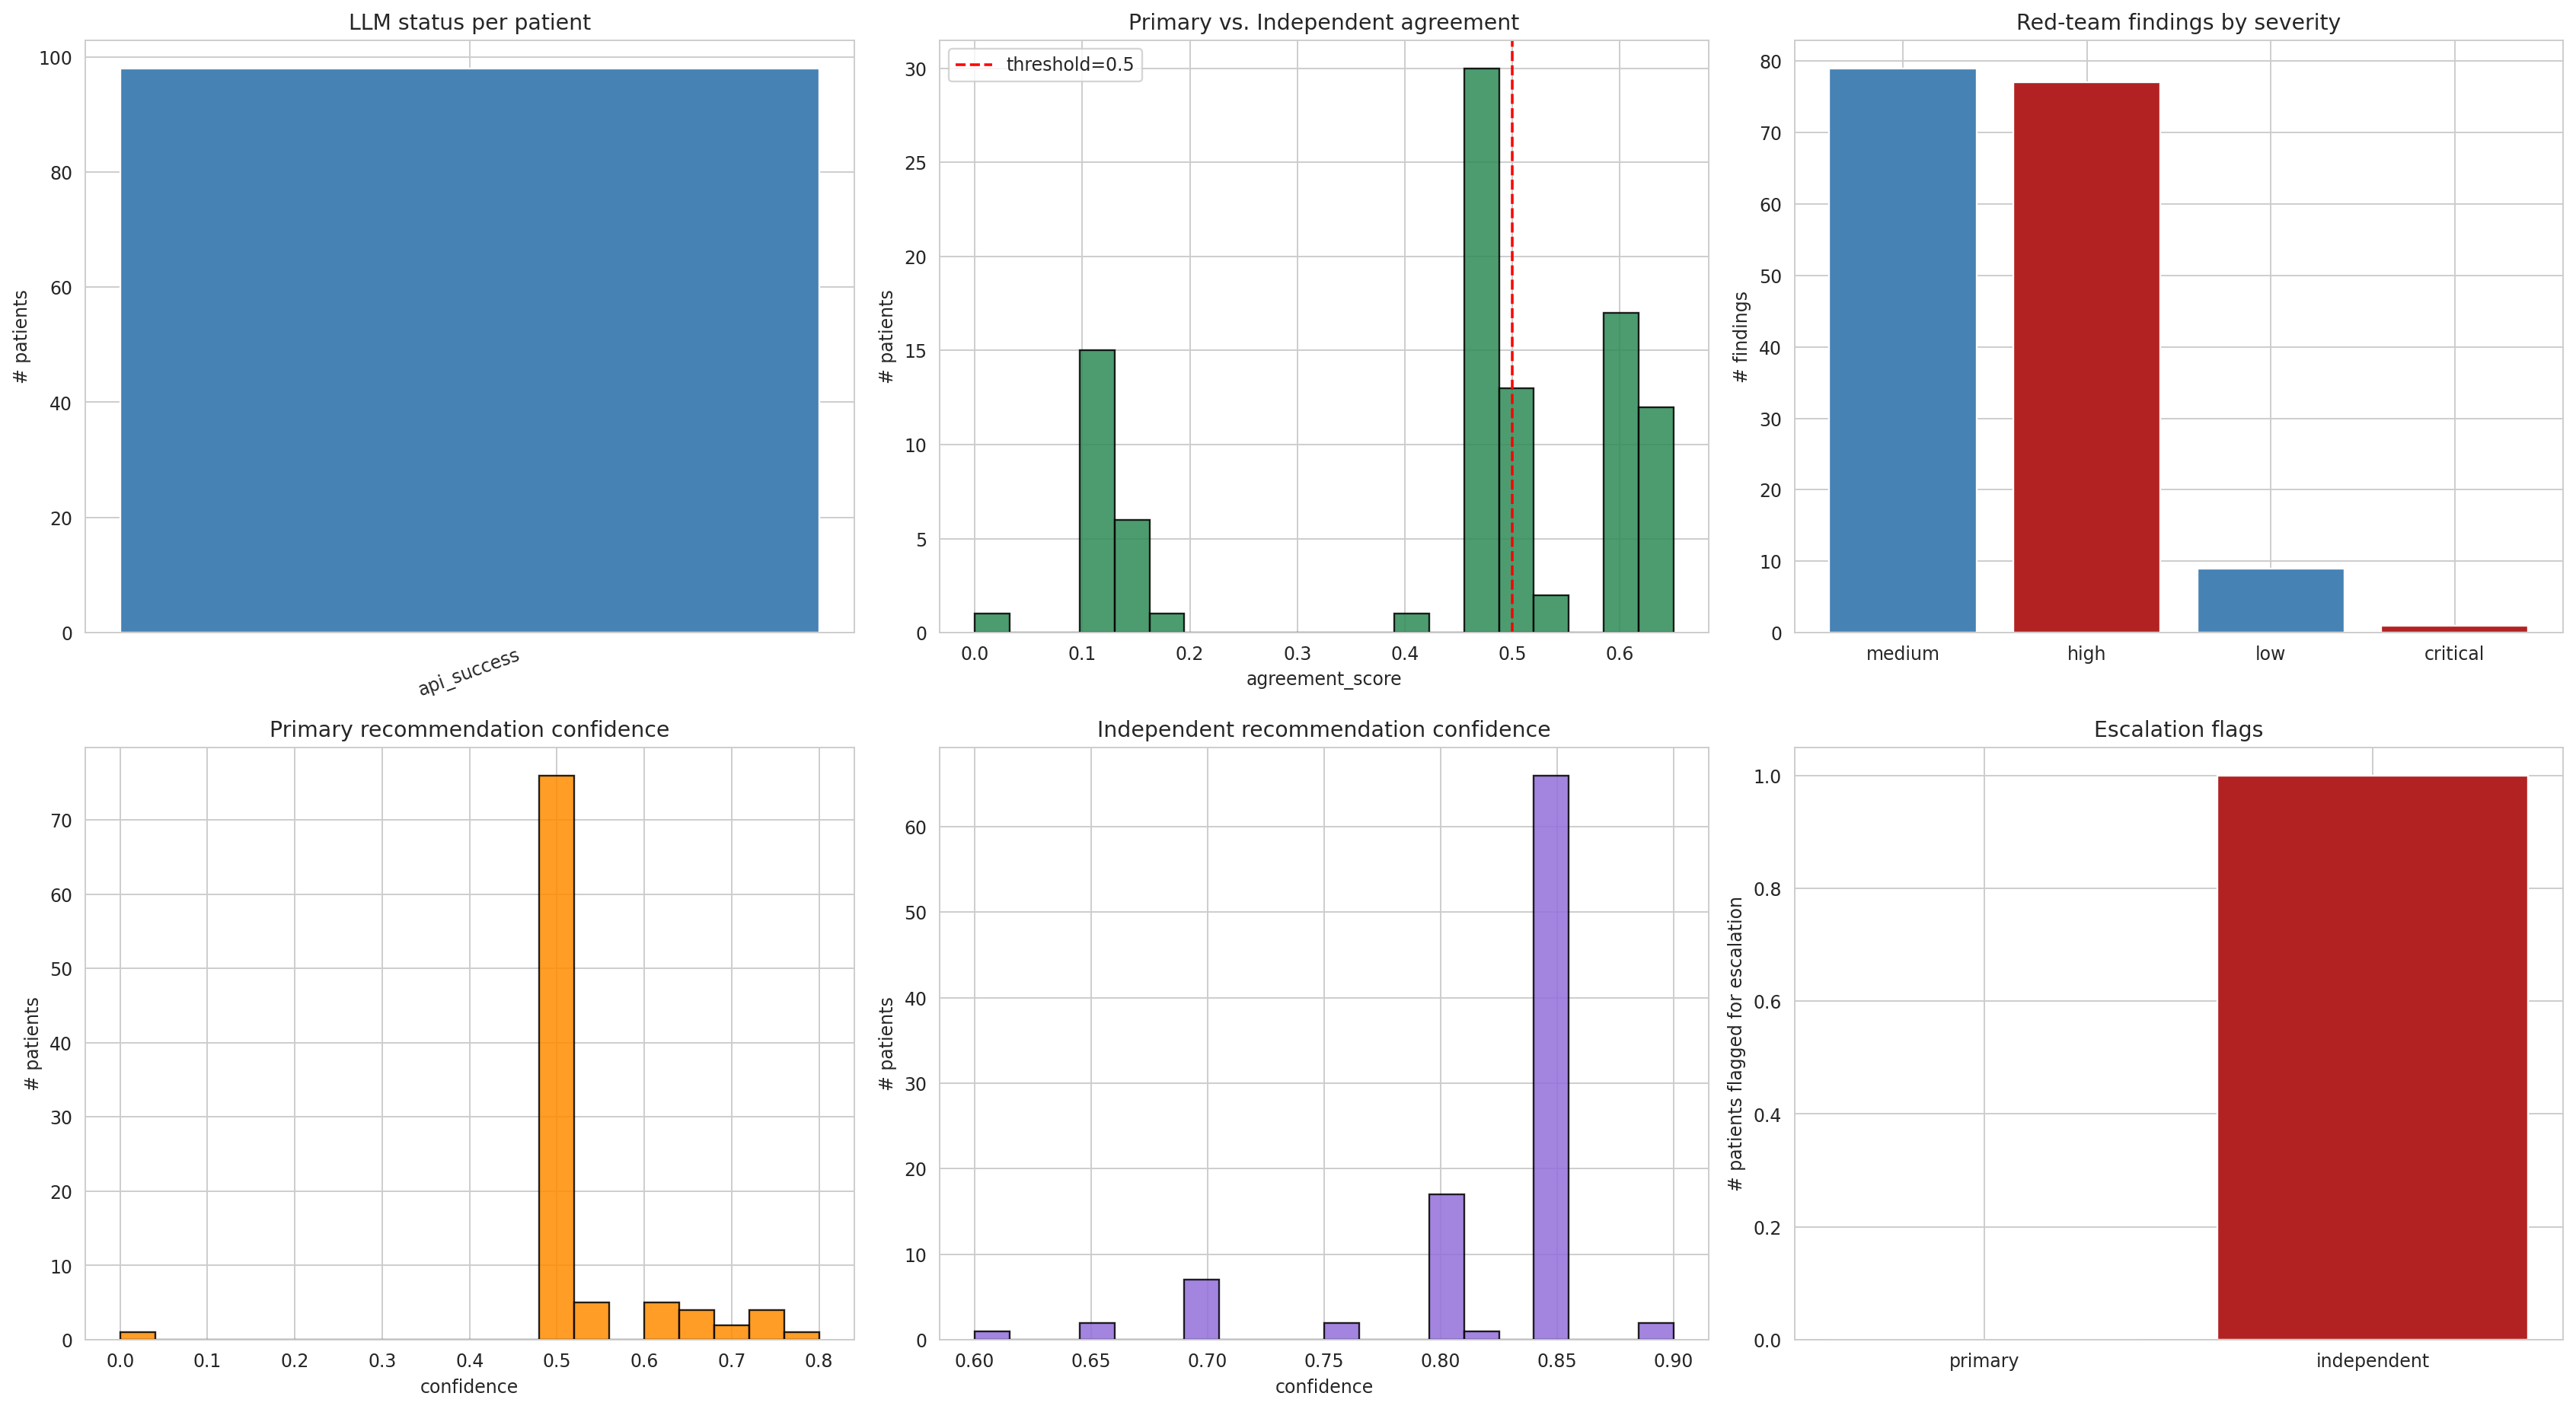

Saved: /kaggle/working/VERIONCO_outputs/07/orchestration_dashboard.png


,metric,mean,median,std,min,max
0,primary_confidence,0.5260,0.5000,0.0883,0.0,0.8000
1,independent_confidence,0.8227,0.8500,0.0552,0.6,0.9000
2,agreement_score,0.4339,0.4667,0.1904,0.0,0.6500
3,token_jaccard,0.4490,0.3333,0.3832,0.0,1.0000
4,citation_jaccard,0.1554,0.0000,0.2141,0.0,0.6667
5,n_redteam_findings,1.6939,2.0000,0.6487,0.0,3.0000
6,n_redteam_critical_high,0.7959,1.0000,0.6574,0.0,3.0000


In [11]:
# ============================================================
# DASHBOARD
# ============================================================
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

from IPython.display import Image, display as _display

fig, axes = plt.subplots(2, 3, figsize=(20, 11))

# 1. LLM status
sc = flat_df["llm_status"].value_counts()
axes[0, 0].bar(sc.index, sc.values, color="steelblue")
axes[0, 0].set_title("LLM status per patient")
axes[0, 0].set_ylabel("# patients")
axes[0, 0].tick_params(axis="x", rotation=20)

# 2. Agreement score histogram
axes[0, 1].hist(flat_df["agreement_score"].dropna(), bins=20,
                color="seagreen", alpha=0.85, edgecolor="black")
axes[0, 1].axvline(AGREEMENT_BINARY_THRESHOLD, color="red", linestyle="--",
                   label=f"threshold={AGREEMENT_BINARY_THRESHOLD}")
axes[0, 1].set_xlabel("agreement_score")
axes[0, 1].set_ylabel("# patients")
axes[0, 1].set_title("Primary vs. Independent agreement")
axes[0, 1].legend()

# 3. Red-team findings severity distribution
all_sev = []
for _, r in all_results.items():
    for f in r.get("redteam_findings", []):
        all_sev.append(f.get("severity", "unknown"))
if all_sev:
    sev_counts = pd.Series(all_sev).value_counts()
    axes[0, 2].bar(sev_counts.index, sev_counts.values,
                   color=["firebrick" if s in ("high", "critical") else "steelblue"
                          for s in sev_counts.index])
    axes[0, 2].set_title("Red-team findings by severity")
    axes[0, 2].set_ylabel("# findings")
else:
    axes[0, 2].text(0.5, 0.5, "No red-team findings", ha="center", va="center")
    axes[0, 2].set_title("Red-team findings by severity")

# 4. Primary confidence histogram
axes[1, 0].hist(flat_df["primary_confidence"].dropna(), bins=20,
                color="darkorange", alpha=0.85, edgecolor="black")
axes[1, 0].set_xlabel("confidence")
axes[1, 0].set_ylabel("# patients")
axes[1, 0].set_title("Primary recommendation confidence")

# 5. Independent confidence histogram
axes[1, 1].hist(flat_df["independent_confidence"].dropna(), bins=20,
                color="mediumpurple", alpha=0.85, edgecolor="black")
axes[1, 1].set_xlabel("confidence")
axes[1, 1].set_ylabel("# patients")
axes[1, 1].set_title("Independent recommendation confidence")

# 6. Escalation flags
esc_prim = int(flat_df["primary_escalation_flag"].sum())
esc_ind  = int(flat_df["independent_escalation_flag"].sum())
axes[1, 2].bar(["primary", "independent"], [esc_prim, esc_ind],
               color=["steelblue", "firebrick"])
axes[1, 2].set_ylabel("# patients flagged for escalation")
axes[1, 2].set_title("Escalation flags")

plt.tight_layout()
dash = NB_OUTPUT / "orchestration_dashboard.png"
plt.savefig(dash, dpi=170, bbox_inches="tight")
_display(Image(filename=str(dash)))
plt.close(fig)
print("Saved:", dash)

summary_rows = []
for col in ["primary_confidence", "independent_confidence",
            "agreement_score", "token_jaccard", "citation_jaccard",
            "n_redteam_findings", "n_redteam_critical_high"]:
    if col in flat_df.columns:
        summary_rows.append({
            "metric": col,
            "mean":   round(float(flat_df[col].mean()), 4),
            "median": float(flat_df[col].median()),
            "std":    round(float(flat_df[col].std()), 4),
            "min":    float(flat_df[col].min()),
            "max":    float(flat_df[col].max()),
        })
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(NB_OUTPUT / "orchestration_distribution_summary.csv", index=False)
display(summary_df)

In [12]:
import gc
# ============================================================
# OUTPUTS — Final inventory, zip, and completion banner
# ============================================================
import shutil
from pathlib import Path

outputs = []
for p in sorted(NB_OUTPUT.rglob("*")):
    if p.is_file():
        outputs.append({
            "file":       str(p.relative_to(NB_OUTPUT)),
            "size_bytes": p.stat().st_size,
        })

inventory_df = pd.DataFrame(outputs)
display(inventory_df)

total_size_mb = inventory_df["size_bytes"].sum() / (1024 * 1024) if len(inventory_df) else 0
print(f"\nTotal files:       {len(inventory_df)}")
print(f"Total size:        {total_size_mb:.2f} MB")
print(f"Output directory:  {NB_OUTPUT}")

zip_stem = OUTPUT_ROOT / "07_artifacts"
zip_path = Path(str(zip_stem) + ".zip")

if zip_path.exists():
    zip_path.unlink()
    print(f"Removed old zip: {zip_path.name}")

shutil.make_archive(
    base_name=str(zip_stem),
    format="zip",
    root_dir=str(NB_OUTPUT),
)

zip_size_mb = zip_path.stat().st_size / (1024 * 1024)
print(f"\n✓ Zipped artifacts")
print(f"  Path:  {zip_path}")
print(f"  Size:  {zip_size_mb:.2f} MB")

print("\n" + "=" * 50)
print("VERIONCO NOTEBOOK 07 COMPLETE")
print("=" * 50)
print(f"Artifacts:      {NB_OUTPUT}")
print(f"Archive:        {zip_path}")
print(f"Prompt version: {PROMPT_VERSION}")
print(f"LLM model:      {LLM_MODEL}")
if llm:
    print(f"API calls:      {llm.calls_this_run}")
    print(f"Cache hits:     {llm.cache_hits}")
    print(f"JSON repairs:   {llm.json_repairs}")
print(f"Files in zip:   {len(inventory_df)}")
print(f"Zip size:       {zip_size_mb:.2f} MB")
print("=" * 50)

gc.collect()

,file,size_bytes
0,agreement_matrix.csv,5657
1,orchestration_all.json,290332
2,orchestration_dashboard.png,181956
3,orchestration_distribution_summary.csv,354
4,orchestration_flat.csv,32607
...,...,...
104,primary_recommendations.csv,4203
105,redteam_results.csv,18429
106,run_summary.json,318
107,second_opinions.csv,5667



Total files:       109
Total size:        0.78 MB
Output directory:  /kaggle/working/VERIONCO_outputs/07

✓ Zipped artifacts
  Path:  /kaggle/working/VERIONCO_outputs/07_artifacts.zip
  Size:  0.30 MB

VERIONCO NOTEBOOK 07 COMPLETE
Artifacts:      /kaggle/working/VERIONCO_outputs/07
Archive:        /kaggle/working/VERIONCO_outputs/07_artifacts.zip
Prompt version: 07_v5
LLM model:      gemini-3.5-flash-lite
API calls:      294
Cache hits:     0
JSON repairs:   4
Files in zip:   109
Zip size:       0.30 MB


9

In [13]:
print(f"primary_is_punt:     {flat_df['primary_is_punt'].sum()} / {len(flat_df)} "
      f"({100 * flat_df['primary_is_punt'].mean():.1f}%)")
print(f"independent_is_punt: {flat_df['independent_is_punt'].sum()} / {len(flat_df)} "
      f"({100 * flat_df['independent_is_punt'].mean():.1f}%)")
print(f"both_punt:           {(flat_df['primary_is_punt'] & flat_df['independent_is_punt']).sum()}")

primary_is_punt:     0 / 98 (0.0%)
independent_is_punt: 1 / 98 (1.0%)
both_punt:           0


In [14]:
display(flat_df[["patient_id", "primary_treatment", "independent_treatment",
                 "primary_escalation_flag", "named_drug_match", "both_escalated",
                 "agreement_binary"]].head(20))

,patient_id,primary_treatment,independent_treatment,primary_escalation_flag,named_drug_match,both_escalated,agreement_binary
0,TCGA-05-4244,Sotorasib,Carboplatin+Pemetrexed,False,False,False,False
1,TCGA-05-4245,Carboplatin+Pemetrexed,Carboplatin+Pemetrexed,False,True,False,True
2,TCGA-05-4249,Sotorasib,Carboplatin+Pemetrexed,False,False,False,False
3,TCGA-05-4250,Sotorasib,Carboplatin+Pemetrexed,False,False,False,False
4,TCGA-05-4382,Pembrolizumab,"Pembrolizumab (TMB-high, guideline-supported)",False,True,False,False
5,TCGA-05-4384,Carboplatin+Pemetrexed,Carboplatin+Pemetrexed (platinum doublet),False,True,False,False
6,TCGA-05-4390,Pembrolizumab,Pembrolizumab,False,True,False,True
7,TCGA-05-4395,Carboplatin+Pemetrexed,Carboplatin+Pemetrexed,False,True,False,True
8,TCGA-05-4396,Pembrolizumab,"Pembrolizumab (TMB-high, guideline-supported)",False,True,False,True
9,TCGA-05-4397,Alpelisib,Pembrolizumab,False,False,False,False


In [ ]:
# ============================================================
# EXPORT & DOWNLOAD ARTIFACT BUNDLE
# ============================================================
import shutil
from pathlib import Path
try:
    from IPython.display import FileLink, display
except ImportError:
    def FileLink(p): return p
    def display(*a): pass

export_dir = OUTPUT_ROOT / 'exports'
export_dir.mkdir(parents=True, exist_ok=True)
zip_name = f'verionco_outputs_{NB_OUTPUT.name}'
zip_path = export_dir / zip_name

# Package NB_OUTPUT into zip
shutil.make_archive(str(zip_path), 'zip', NB_OUTPUT)
final_zip = export_dir / f'{zip_name}.zip'

print('=' * 60)
print(f'VERIONCO NOTEBOOK {NB_OUTPUT.name} COMPLETE')
print(f'Artifact bundle created: {final_zip}')
print(f'Archive size: {final_zip.stat().st_size / (1024*1024):.2f} MB')
print('=' * 60)

# Display download link (clickable in Kaggle/Jupyter)
display(FileLink(str(final_zip)))
